In [1]:
%% MIT 18.03 Lecture 4: Newton's Law of Cooling, Integrating Factor & Transients
% Description: Simulates thermal dynamics dx/dt + k*x = k*T_ext(t) under ramp input.
%              Analyzes transient decay, steady-state lag, and nullcline crossings.
%
% % Required Toolboxes: None (Base MATLAB only).
%
% % MBD Concept Mapping: Demonstrates first-order thermal plant dynamics (RC equivalent),
%                      decomposition into transient and steady-state responses,
%                      and ramp-tracking velocity error: e_ss = Slope / k.


clear; clc; close all;


%% 1. System Parameters (From MIT 18.03 Lecture 4 Cooler Benchmark)
k = 1/3;                   % Thermal coupling constant (1/tau), tau = 3 hours
T_ext_slope = 6;           % Ambient ramp rate: 6 deg/hour
T_ext_0 = 60;              % Initial ambient temperature at t = 0 (10:00 AM)
x0_lecture = 32;           % Initial cooler temperature (ice cold)
t_span = [0, 15];          % Simulation time horizon (0 to 15 hours)


% Analytical Steady-State Solution (Particular Solution x_p):
% x_p(t) = (T_ext_0 - T_ext_slope/k) + T_ext_slope*t = (60 - 18) + 6t = 42 + 6t
steady_state_lag = T_ext_slope / k; % Velocity error constant = 18 deg


fprintf('=== First-Order Thermal System Parameters ===\n');

=== First-Order Thermal System Parameters ===

In [2]:
fprintf('Coupling Constant (k)       : %.4f (1/h)\n', k);

Coupling Constant (k)       : 0.3333 (1/h)

In [3]:
fprintf('Time Constant (tau = 1/k)   : %.2f hours\n', 1/k);

Time Constant (tau = 1/k)   : 3.00 hours

In [4]:
fprintf('Steady-State Lag (e_ss)     : %.2f deg (Slope / k)\n', steady_state_lag);

Steady-State Lag (e_ss)     : 18.00 deg (Slope / k)

In [5]:
fprintf('=============================================\n\n');


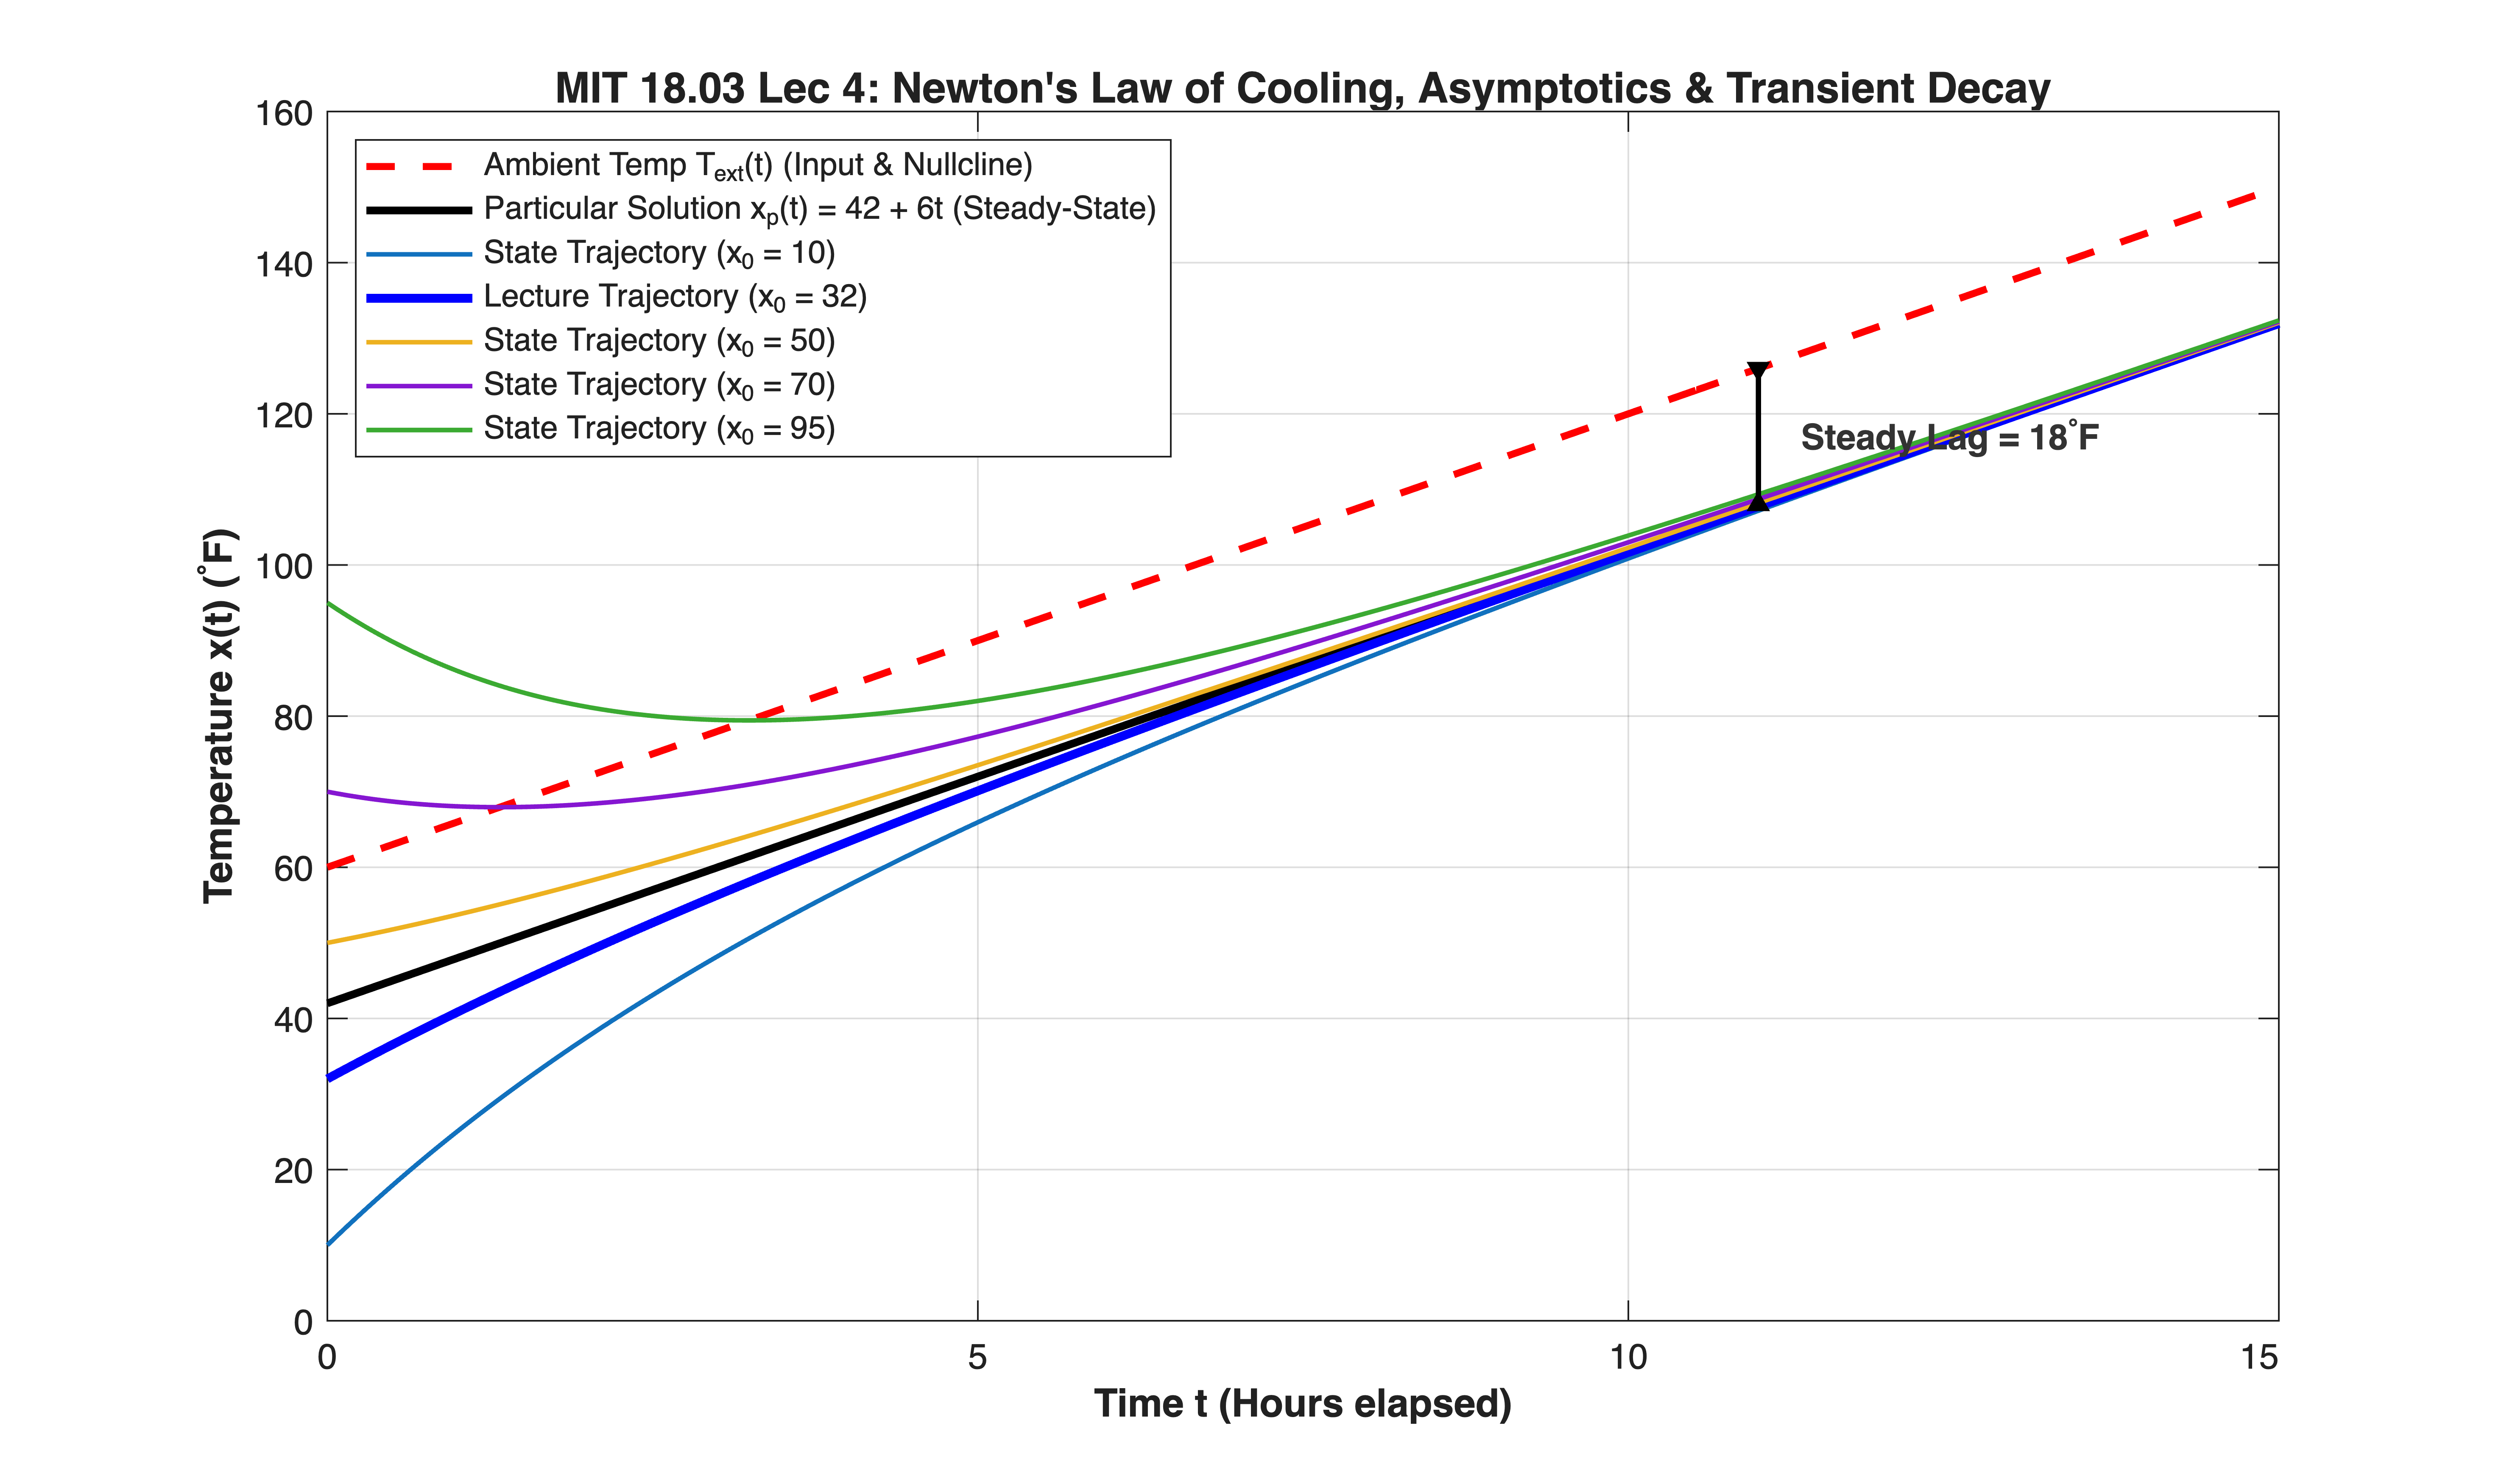

In [6]:


%% 2. Function Definitions for Dynamic Simulation
t_eval = linspace(t_span(1), t_span(2), 500);


% Input Signal: Ambient temperature ramp
T_ext_func = @(t) T_ext_0 + T_ext_slope * t;


% Particular Solution (Steady-State Attractor)
x_p_func = @(t) (T_ext_0 - steady_state_lag) + T_ext_slope * t;


% Nullcline where dx/dt = 0: x = T_ext(t)
nullcline_func = @(t) T_ext_func(t);


% ODE Definition: dx/dt = k*(T_ext(t) - x)
ode_cooler = @(t, x) k * (T_ext_func(t) - x);


%% 3. Numerical Integration across Multiple Initial States
initial_temps = [10, 32, 50, 70, 95]; % Various initial temperatures
trajectory_data = cell(length(initial_temps), 1);
opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);


for idx = 1:length(initial_temps)
    x_init = initial_temps(idx);
    [t_sol, x_sol] = ode45(ode_cooler, t_eval, x_init, opts);
    trajectory_data{idx}.t = t_sol;
    trajectory_data{idx}.x = x_sol;
    trajectory_data{idx}.x0 = x_init;
end


%% 4. Visualization & Transient Analysis
figure('Color', [1 1 1], 'Position', [150, 150, 950, 560]);
hold on; grid on; box on;


% Plot Ambient Input & Particular Solution
plot(t_eval, T_ext_func(t_eval), 'r--', 'LineWidth', 2.0, ...
    'DisplayName', 'Ambient Temp T_{ext}(t) (Input & Nullcline)');
plot(t_eval, x_p_func(t_eval), 'k-', 'LineWidth', 2.2, ...
    'DisplayName', 'Particular Solution x_p(t) = 42 + 6t (Steady-State)');


% Plot Simulated State Trajectories
palette = lines(length(initial_temps));
for idx = 1:length(initial_temps)
    x_init = trajectory_data{idx}.x0;
    if x_init == x0_lecture
        plot(trajectory_data{idx}.t, trajectory_data{idx}.x, 'b-', 'LineWidth', 2.5, ...
            'DisplayName', sprintf('Lecture Trajectory (x_0 = %d)', x_init));
    else
        plot(trajectory_data{idx}.t, trajectory_data{idx}.x, 'Color', palette(idx,:), ...
            'LineWidth', 1.3, 'DisplayName', sprintf('State Trajectory (x_0 = %d)', x_init));
    end
end


% Annotations for Transient & Lag
xlabel('Time t (Hours elapsed)', 'FontSize', 11, 'FontWeight', 'bold');
ylabel('Temperature x(t) (^\circF)', 'FontSize', 11, 'FontWeight', 'bold');
title("MIT 18.03 Lec 4: Newton's Law of Cooling, Asymptotics & Transient Decay", ...
    'FontSize', 12, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 9);


% Visual indicator of the 18 deg steady-state velocity lag
t_mark = 11;
x_p_val = x_p_func(t_mark);
t_ext_val = T_ext_func(t_mark);
% Draw vertical lag dimension line with arrow endpoints
plot([t_mark, t_mark], [x_p_val, t_ext_val], 'k-', 'LineWidth', 1.5, 'HandleVisibility', 'off');
plot(t_mark, x_p_val, 'k^', 'MarkerFaceColor', 'k', 'MarkerSize', 5, 'HandleVisibility', 'off');
plot(t_mark, t_ext_val, 'kv', 'MarkerFaceColor', 'k', 'MarkerSize', 5, 'HandleVisibility', 'off');
text(t_mark + 0.3, (x_p_val + t_ext_val)/2, sprintf('Steady Lag = %.0f^\\circF', steady_state_lag), ...
    'FontSize', 10, 'FontWeight', 'bold', 'Color', [0.2 0.2 0.2]);


xlim([t_span(1), t_span(2)]);
ylim([0, 160]);
hold off;